**A Behavior Consistency Framework for AI-Based Suspicious Transaction Detection in Banking**

In [ ]:
!pip install xgboost

In [ ]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split

from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score

from sklearn.metrics import recall_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report

from xgboost import XGBClassifier


In [ ]:
df = pd.read_csv("/content/paysim dataset.csv")

row_count = df.shape[0]

print(f"Total data rows: {row_count}")

Total data rows: 6362620


In [ ]:
!wc -l "/content/paysim dataset.csv"

6362621 /content/paysim dataset.csv


In [ ]:
print('--- Current DataFrame Info ---')
df.info()

print('\n--- Current Null Value Counts ---')
df.isnull().sum()

--- Current DataFrame Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6362620 entries, 0 to 6362619
Data columns (total 11 columns):
 #   Column          Dtype  
---  ------          -----  
 0   step            int64  
 1   type            object 
 2   amount          float64
 3   nameOrig        object 
 4   oldbalanceOrg   float64
 5   newbalanceOrig  float64
 6   nameDest        object 
 7   oldbalanceDest  float64
 8   newbalanceDest  float64
 9   isFraud         int64  
 10  isFlaggedFraud  int64  
dtypes: float64(5), int64(3), object(3)
memory usage: 534.0+ MB

--- Current Null Value Counts ---


,0
step,0
type,0
amount,0
nameOrig,0
oldbalanceOrg,0
newbalanceOrig,0
nameDest,0
oldbalanceDest,0
newbalanceDest,0
isFraud,0


In [ ]:
print("Dataset Loaded Successfully!")


Dataset Loaded Successfully!


In [ ]:
df.head()

,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0
1,1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0
2,1,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1,0
3,1,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1,0
4,1,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0,0


In [ ]:
print(f"Shape after dropping null values: {df.shape}")

Shape after dropping null values: (6362620, 11)


In [ ]:
print(df.columns)


Index(['step', 'type', 'amount', 'nameOrig', 'oldbalanceOrg', 'newbalanceOrig',
       'nameDest', 'oldbalanceDest', 'newbalanceDest', 'isFraud',
       'isFlaggedFraud'],
      dtype='object')


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6362620 entries, 0 to 6362619
Data columns (total 11 columns):
 #   Column          Dtype  
---  ------          -----  
 0   step            int64  
 1   type            object 
 2   amount          float64
 3   nameOrig        object 
 4   oldbalanceOrg   float64
 5   newbalanceOrig  float64
 6   nameDest        object 
 7   oldbalanceDest  float64
 8   newbalanceDest  float64
 9   isFraud         int64  
 10  isFlaggedFraud  int64  
dtypes: float64(5), int64(3), object(3)
memory usage: 534.0+ MB


In [ ]:
df.isnull().sum()


,0
step,0
type,0
amount,0
nameOrig,0
oldbalanceOrg,0
newbalanceOrig,0
nameDest,0
oldbalanceDest,0
newbalanceDest,0
isFraud,0


In [ ]:
df = df.dropna()

In [ ]:
df.isnull().sum()

,0
step,0
type,0
amount,0
nameOrig,0
oldbalanceOrg,0
newbalanceOrig,0
nameDest,0
oldbalanceDest,0
newbalanceDest,0
isFraud,0


In [ ]:
print(df["isFraud"].value_counts())

isFraud
0    6354407
1       8213
Name: count, dtype: int64


In [ ]:
fraud_percentage = (df["isFraud"].sum() / len(df)) * 100

print(f"Fraud Percentage: {fraud_percentage:.6f}%")

Fraud Percentage: 0.129082%


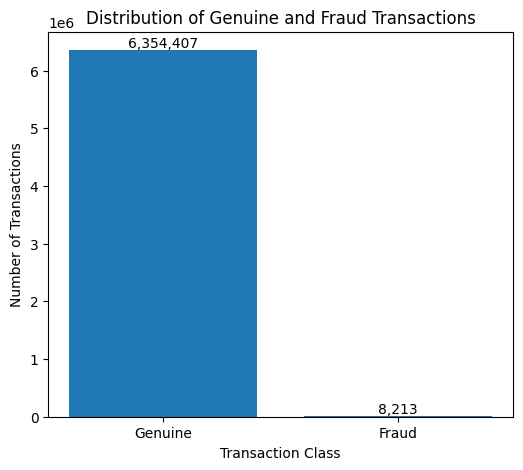

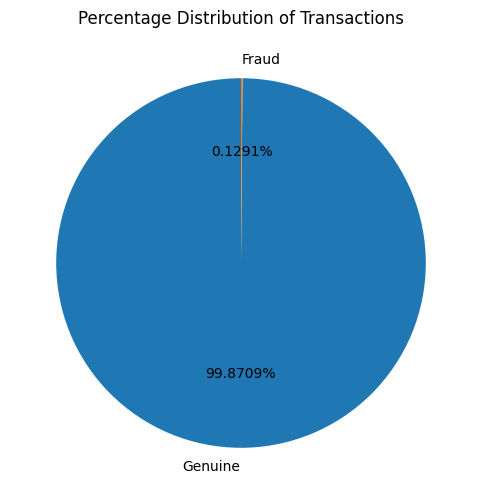

In [ ]:
fraud_counts = df["isFraud"].value_counts()

# ----------------------------
# Bar Chart
# ----------------------------
plt.figure(figsize=(6,5))

bars = plt.bar(
    ["Genuine", "Fraud"],
    fraud_counts.values
)

plt.title("Distribution of Genuine and Fraud Transactions")
plt.xlabel("Transaction Class")
plt.ylabel("Number of Transactions")

# Display values on top of bars
for bar in bars:
    y = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width()/2,
        y,
        f"{int(y):,}",
        ha="center",
        va="bottom",
        fontsize=10
    )

plt.show()


# ----------------------------
# Pie Chart
# ----------------------------
plt.figure(figsize=(6,6))

plt.pie(
    fraud_counts.values,
    labels=["Genuine", "Fraud"],
    autopct="%1.4f%%",
    startangle=90
)

plt.title("Percentage Distribution of Transactions")

plt.show()

In [ ]:
df.head()


,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0
1,1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0
2,1,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1,0
3,1,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1,0
4,1,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0,0


In [ ]:
df = df.drop(columns=["isFlaggedFraud"])

In [ ]:
df.head()

,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud
0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0
1,1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0
2,1,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1
3,1,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1
4,1,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0


In [ ]:
print(df["type"].value_counts())

type
CASH_OUT    2237500
PAYMENT     2151495
CASH_IN     1399284
TRANSFER     532909
DEBIT         41432
Name: count, dtype: int64


In [ ]:
df = pd.get_dummies(df, columns=["type"], dtype=int)

In [ ]:
df.head()

,step,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,type_CASH_IN,type_CASH_OUT,type_DEBIT,type_PAYMENT,type_TRANSFER
0,1,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0,0,0,1,0
1,1,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0,0,0,1,0
2,1,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1,0,0,0,0,1
3,1,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1,0,1,0,0,0
4,1,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0,0,0,0,1,0


In [ ]:
X = df.drop(columns=["isFraud", "nameOrig", "nameDest"])
y = df["isFraud"]

In [ ]:
print("Features Shape :", X.shape)
print("Target Shape   :", y.shape)

Features Shape : (6362620, 11)
Target Shape   : (6362620,)


In [ ]:
from sklearn.model_selection import train_test_split

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [ ]:
print("X_train :", X_train.shape)
print("X_test  :", X_test.shape)
print("y_train :", y_train.shape)
print("y_test  :", y_test.shape)

X_train : (5090096, 11)
X_test  : (1272524, 11)
y_train : (5090096,)
y_test  : (1272524,)


In [ ]:
import xgboost
print(xgboost.__version__)


3.4.1


In [ ]:
from xgboost import XGBClassifier

model = XGBClassifier(
    random_state=42,
    eval_metric="logloss"
)

In [ ]:
model.fit(X_train, y_train)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=None, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=None, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=None, n_jobs=None,
              num_parallel_tree=None, ...)

In [ ]:
y_pred = model.predict(X_test)

In [ ]:
print(y_pred[:20])

[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]


In [ ]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy :", accuracy)

Accuracy : 0.9995394978798042


In [ ]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

print(cm)

[[1270704     200]
 [    386    1234]]


In [ ]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00   1270904
           1       0.86      0.76      0.81      1620

    accuracy                           1.00   1272524
   macro avg       0.93      0.88      0.90   1272524
weighted avg       1.00      1.00      1.00   1272524



In [ ]:
print("DataFrame shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

DataFrame shape: (6362620, 14)

Columns:
['step', 'amount', 'nameOrig', 'oldbalanceOrg', 'newbalanceOrig', 'nameDest', 'oldbalanceDest', 'newbalanceDest', 'isFraud', 'type_CASH_IN', 'type_CASH_OUT', 'type_DEBIT', 'type_PAYMENT', 'type_TRANSFER']


In [ ]:
print("Total transactions:", len(df))

print("\nFraud distribution:")
print(df["isFraud"].value_counts())

print("\nFraud percentage:")
print(df["isFraud"].value_counts(normalize=True) * 100)

Total transactions: 6362620

Fraud distribution:
isFraud
0    6354407
1       8213
Name: count, dtype: int64

Fraud percentage:
isFraud
0    99.870918
1     0.129082
Name: proportion, dtype: float64


In [ ]:
print("Current dataframe shape:", df.shape)

print("\nFirst 5 rows:")
display(df.head())

print("\nLast 5 rows:")
display(df.tail())

print("\nUnique fraud values:")
print(df["isFraud"].value_counts())

Current dataframe shape: (6362620, 14)

First 5 rows:


,step,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,type_CASH_IN,type_CASH_OUT,type_DEBIT,type_PAYMENT,type_TRANSFER
0,1,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0,0,0,1,0
1,1,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0,0,0,1,0
2,1,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1,0,0,0,0,1
3,1,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1,0,1,0,0,0
4,1,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0,0,0,0,1,0



Last 5 rows:


,step,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,type_CASH_IN,type_CASH_OUT,type_DEBIT,type_PAYMENT,type_TRANSFER
6362615,743,339682.13,C786484425,339682.13,0.0,C776919290,0.00,339682.13,1,0,1,0,0,0
6362616,743,6311409.28,C1529008245,6311409.28,0.0,C1881841831,0.00,0.00,1,0,0,0,0,1
6362617,743,6311409.28,C1162922333,6311409.28,0.0,C1365125890,68488.84,6379898.11,1,0,1,0,0,0
6362618,743,850002.52,C1685995037,850002.52,0.0,C2080388513,0.00,0.00,1,0,0,0,0,1
6362619,743,850002.52,C1280323807,850002.52,0.0,C873221189,6510099.11,7360101.63,1,0,1,0,0,0



Unique fraud values:
isFraud
0    6354407
1       8213
Name: count, dtype: int64


In [ ]:
# Check for duplicate transactions

print("Total rows:", len(df))

print("Duplicate rows:", df.duplicated().sum())

print("Duplicate percentage:",
      (df.duplicated().sum() / len(df)) * 100)

Total rows: 6362620
Duplicate rows: 0
Duplicate percentage: 0.0


In [ ]:
# Create previous transaction count for each sender-receiver pair

df = df.sort_values("step").copy()

df["previous_pair_count"] = (
    df.groupby(["nameOrig", "nameDest"]).cumcount()
)

print(df[["nameOrig", "nameDest", "previous_pair_count"]].head(10))

       nameOrig     nameDest  previous_pair_count
23   C504336483  M1404932042                    0
22  C1959239586   C515132998                    0
21  C1566511282  C1973538135                    0
20    C20804602  M1344519051                    0
19  C1670993182  C1100439041                    0
18  C2033524545   M473053293                    0
17  C1237762639  M1877062907                    0
16   C761750706  M1731217984                    0
15   C905080434   C476402209                    0
14  C1026483832  M1635378213                    0


In [ ]:
# Create Receiver Familiarity Score (RFS)

df["RFS"] = df["previous_pair_count"].apply(
    lambda x: 0.2 if x == 0
    else 0.5 if x <= 2
    else 1.0
)

# Check RFS distribution
print(df["RFS"].value_counts().sort_index())

# Display sample
print("\nSample RFS values:")
print(df[["nameOrig", "nameDest", "previous_pair_count", "RFS"]].head(10))

RFS
0.2    6362620
Name: count, dtype: int64

Sample RFS values:
       nameOrig     nameDest  previous_pair_count  RFS
23   C504336483  M1404932042                    0  0.2
22  C1959239586   C515132998                    0  0.2
21  C1566511282  C1973538135                    0  0.2
20    C20804602  M1344519051                    0  0.2
19  C1670993182  C1100439041                    0  0.2
18  C2033524545   M473053293                    0  0.2
17  C1237762639  M1877062907                    0  0.2
16   C761750706  M1731217984                    0  0.2
15   C905080434   C476402209                    0  0.2
14  C1026483832  M1635378213                    0  0.2


In [ ]:
# Check whether any sender-receiver pair occurs more than once

pair_counts = df.groupby(
    ["nameOrig", "nameDest"]
).size()

print("Total unique sender-receiver pairs:", len(pair_counts))
print("Pairs occurring more than once:", (pair_counts > 1).sum())
print("Maximum transactions for any pair:", pair_counts.max())

print("\nRepeated pair examples:")
print(pair_counts[pair_counts > 1].head(10))

Total unique sender-receiver pairs: 6362620
Pairs occurring more than once: 0
Maximum transactions for any pair: 1

Repeated pair examples:
Series([], dtype: int64)


In [ ]:
# Check how many transactions each sender has

sender_counts = df["nameOrig"].value_counts()

print("Unique senders:", sender_counts.size)
print("Maximum transactions by one sender:", sender_counts.max())
print("Senders with more than 1 transaction:", (sender_counts > 1).sum())

print("\nExample senders with multiple transactions:")
print(sender_counts[sender_counts > 1].head(10))

Unique senders: 6353307
Maximum transactions by one sender: 3
Senders with more than 1 transaction: 9298

Example senders with multiple transactions:
nameOrig
C1999539787    3
C1530544995    3
C1677795071    3
C1832548028    3
C724452879     3
C1462946854    3
C1784010646    3
C1976208114    3
C1902386530    3
C1065307291    3
Name: count, dtype: int64


In [ ]:
print("Unique receiver IDs:", df["nameDest"].nunique())
print("Total transactions:", len(df))

print("\nReceiver types:")
print(df["nameDest"].str[0].value_counts())

Unique receiver IDs: 2722362
Total transactions: 6362620

Receiver types:
nameDest
C    4211125
M    2151495
Name: count, dtype: int64


In [ ]:
receiver_counts = df["nameDest"].value_counts()

print("Receivers with more than 1 transaction:",
      (receiver_counts > 1).sum())

print("Maximum transactions received by one receiver:",
      receiver_counts.max())

print("\nExample repeated receivers:")
print(receiver_counts[receiver_counts > 1].head(10))

Receivers with more than 1 transaction: 459658
Maximum transactions received by one receiver: 113

Example repeated receivers:
nameDest
C1286084959    113
C985934102     109
C665576141     105
C2083562754    102
C248609774     101
C1590550415    101
C451111351      99
C1789550256     99
C1360767589     98
C1023714065     97
Name: count, dtype: int64


In [ ]:
# Create previous transaction count for each receiver

df = df.sort_values("step").copy()

df["previous_receiver_count"] = (
    df.groupby("nameDest").cumcount()
)

# Check the result
print(df[["nameDest", "previous_receiver_count"]].head(10))

print("\nMaximum previous receiver count:",
      df["previous_receiver_count"].max())

print("\nTransactions with previous receiver history:",
      (df["previous_receiver_count"] > 0).sum())

        nameDest  previous_receiver_count
168  C1209271652                        0
169  C2083562754                        0
170   C557041912                        0
171  C1590550415                        0
172  C1435804085                        0
173   C736709391                        0
174   C240650537                        0
175  C1854778591                        0
156  C1590550415                        1
157   C288665596                        0

Maximum previous receiver count: 112

Transactions with previous receiver history: 3640258


In [ ]:
# Create Receiver Familiarity Score (RFS)
# Based on previous transactions received by the receiver

df["RFS"] = df["previous_receiver_count"].apply(
    lambda x: 0.2 if x == 0
    else 0.5 if x <= 2
    else 1.0
)

# Check RFS distribution
print("RFS Distribution:")
print(df["RFS"].value_counts().sort_index())

print("\nRFS Percentage:")
print(
    (df["RFS"].value_counts(normalize=True).sort_index() * 100)
    .round(2)
)

print("\nSample:")
print(
    df[
        ["nameDest", "previous_receiver_count", "RFS"]
    ].head(15)
)

RFS Distribution:
RFS
0.2    2722362
0.5     842262
1.0    2797996
Name: count, dtype: int64

RFS Percentage:
RFS
0.2    42.79
0.5    13.24
1.0    43.98
Name: proportion, dtype: float64

Sample:
        nameDest  previous_receiver_count  RFS
168  C1209271652                        0  0.2
169  C2083562754                        0  0.2
170   C557041912                        0  0.2
171  C1590550415                        0  0.2
172  C1435804085                        0  0.2
173   C736709391                        0  0.2
174   C240650537                        0  0.2
175  C1854778591                        0  0.2
156  C1590550415                        1  0.5
157   C288665596                        0  0.2
158  C1749186397                        0  0.2
159   C453211571                        0  0.2
304  M1455855843                        0  0.2
305   M256346753                        0  0.2
306   C466505482                        0  0.2


In [ ]:
import numpy as np

# 1. Amount Score: Deviation from average transaction amount
avg_amount = df['amount'].mean()
df['AmountScore'] = 1 - (np.abs(df['amount'] - avg_amount) / (avg_amount + 1e-5))
df['AmountScore'] = df['AmountScore'].clip(0, 1)

# 2. Balance Consistency Score: Checks if origin balance shift matches transaction amount
expected_new_bal = df['oldbalanceOrg'] - df['amount']
bal_diff = np.abs(expected_new_bal - df['newbalanceOrig'])
df['BalanceScore'] = 1 - (bal_diff / (df['amount'] + 1e-5))
df['BalanceScore'] = df['BalanceScore'].clip(0, 1)

# 3. Time Score: Deviation from mean transaction step timing
avg_step = df['step'].mean()
max_step = df['step'].max()
df['TimeScore'] = 1 - (np.abs(df['step'] - avg_step) / max_step)
df['TimeScore'] = df['TimeScore'].clip(0, 1)

# 4. Final Weighted BCS
df['BCS'] = (0.4 * df['AmountScore']) + (0.3 * df['BalanceScore']) + (0.3 * df['TimeScore'])

# Drop helper columns
df.drop(columns=['AmountScore', 'BalanceScore', 'TimeScore'], inplace=True)

# Display summary
print("BCS calculated successfully!\n")
print("BCS Statistics:")
print(df['BCS'].describe())

print("\nSample BCS output:")
print(df[['amount', 'step', 'RFS', 'BCS']].head(10))

BCS calculated successfully!

BCS Statistics:
count    6.362620e+06
mean     4.603983e-01
std      1.531032e-01
min      9.908368e-02
25%      3.118494e-01
50%      4.762149e-01
75%      5.850893e-01
max      9.984511e-01
Name: BCS, dtype: float64

Sample BCS output:
        amount  step  RFS       BCS
168  114712.48     1  0.2  0.457240
169   89038.75     1  0.2  0.400143
170    1341.58     1  0.2  0.205111
171   44443.08     1  0.2  0.300966
172   34729.64     1  0.2  0.279364
173  105979.34     1  0.2  0.437818
174   57794.61     1  0.2  0.330659
175   15918.79     1  0.2  0.237530
156  186447.51     1  0.5  0.587482
157   81029.86     1  0.2  0.382332


In [ ]:
# Display rows where RFS is 0.5 or 1.0
print("Sample of transactions with RFS = 0.5 or 1.0:")
df[df['RFS'] > 0.2][['nameDest', 'previous_receiver_count', 'RFS']].head(10)

Sample of transactions with RFS = 0.5 or 1.0:


,nameDest,previous_receiver_count,RFS
156,C1590550415,1,0.5
167,C476800120,1,0.5
354,C1749186397,1,0.5
357,C453211571,1,0.5
358,C1590550415,2,0.5
359,C1590550415,3,1.0
362,C1590550415,4,1.0
364,C1531333864,1,0.5
369,C240650537,1,0.5
375,C1590550415,5,1.0


In [ ]:
from sklearn.model_selection import train_test_split
from imblearn.over_sampling import SMOTE

# 1. Target variable
y = df['isFraud']

# 2. Enhanced feature columns (exclude raw IDs, flags, and targets)
exclude_cols = ['isFraud', 'isFlaggedFraud', 'nameOrig', 'nameDest', 'previous_receiver_count']
feature_cols = [col for col in df.columns if col not in exclude_cols]

X = df[feature_cols]

print(f"Total Enhanced Features: {len(feature_cols)}")
print("Feature Columns:", feature_cols)

# 3. Train-Test Split (80/20 split, stratified)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"\n--- BEFORE SMOTE ---")
print(f"X_train Shape: {X_train.shape}")
print(f"Genuine cases in Train (0): {(y_train == 0).sum()}")
print(f"Fraud cases in Train (1): {(y_train == 1).sum()}")

# 4. Apply SMOTE strictly on Training Set
print("\nApplying SMOTE (sampling_strategy=0.2)...")
smote = SMOTE(sampling_strategy=0.2, random_state=42)
X_train_res, y_train_res = smote.fit_resample(X_train, y_train)

print(f"\n--- AFTER SMOTE ---")
print(f"X_train_res Shape: {X_train_res.shape}")
print(f"Genuine cases in Train (0): {(y_train_res == 0).sum()}")
print(f"Fraud cases in Train (1): {(y_train_res == 1).sum()}")
print(f"\nX_test Shape (Untouched): {X_test.shape}")

Total Enhanced Features: 14
Feature Columns: ['step', 'amount', 'oldbalanceOrg', 'newbalanceOrig', 'oldbalanceDest', 'newbalanceDest', 'type_CASH_IN', 'type_CASH_OUT', 'type_DEBIT', 'type_PAYMENT', 'type_TRANSFER', 'previous_pair_count', 'RFS', 'BCS']

--- BEFORE SMOTE ---
X_train Shape: (5090096, 14)
Genuine cases in Train (0): 5083526
Fraud cases in Train (1): 6570

Applying SMOTE (sampling_strategy=0.2)...

--- AFTER SMOTE ---
X_train_res Shape: (6100231, 14)
Genuine cases in Train (0): 5083526
Fraud cases in Train (1): 1016705

X_test Shape (Untouched): (1272524, 14)


In [ ]:
from xgboost import XGBClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, precision_score, recall_score, f1_score

# 1. Initialize and train Proposed XGBoost Model
print("Training Proposed XGBoost Model with RFS, BCS, and SMOTE...")
model_proposed = XGBClassifier(
    eval_metric='logloss',
    random_state=42,
    n_estimators=100
)

model_proposed.fit(X_train_res, y_train_res)

# 2. Predict on untouched test set
y_pred = model_proposed.predict(X_test)

# 3. Display Performance Metrics
print("\n=== PROPOSED MODEL EVALUATION ===")
print(f"Accuracy:  {accuracy_score(y_test, y_pred):.6f}")
print(f"Precision: {precision_score(y_test, y_pred):.6f}")
print(f"Recall:    {recall_score(y_test, y_pred):.6f}")
print(f"F1-Score:  {f1_score(y_test, y_pred):.6f}")

print("\nConfusion Matrix:")
cm = confusion_matrix(y_test, y_pred)
print(cm)

print("\nClassification Report:")
print(classification_report(y_test, y_pred, digits=4))

Training Proposed XGBoost Model with RFS, BCS, and SMOTE...

=== PROPOSED MODEL EVALUATION ===
Accuracy:  0.998968
Precision: 0.557015
Recall:    0.981132
F1-Score:  0.710602

Confusion Matrix:
[[1269599    1282]
 [     31    1612]]

Classification Report:
              precision    recall  f1-score   support

           0     1.0000    0.9990    0.9995   1270881
           1     0.5570    0.9811    0.7106      1643

    accuracy                         0.9990   1272524
   macro avg     0.7785    0.9901    0.8550   1272524
weighted avg     0.9994    0.9990    0.9991   1272524



In [ ]:
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

# 1. Define baseline feature list (11 features without RFS, BCS, or previous_pair_count)
baseline_features = [
    'step', 'amount', 'oldbalanceOrg', 'newbalanceOrig',
    'oldbalanceDest', 'newbalanceDest', 'type_CASH_IN',
    'type_CASH_OUT', 'type_DEBIT', 'type_PAYMENT', 'type_TRANSFER'
]

# 2. Train XGBoost on Baseline Features ONLY (with SMOTE)
print("Training XGBoost on Baseline Features + SMOTE (No Novelty)...")
model_smote_only = XGBClassifier(
    eval_metric='logloss',
    random_state=42,
    n_estimators=100
)

model_smote_only.fit(X_train_res[baseline_features], y_train_res)

# 3. Predict on Test Set (Baseline features only)
y_pred_smote_only = model_smote_only.predict(X_test[baseline_features])

# 4. Calculate Metrics for Baseline + SMOTE
acc_smote = accuracy_score(y_test, y_pred_smote_only)
prec_smote = precision_score(y_test, y_pred_smote_only)
rec_smote = recall_score(y_test, y_pred_smote_only)
f1_smote = f1_score(y_test, y_pred_smote_only)
cm_smote = confusion_matrix(y_test, y_pred_smote_only)

print("\n=== STAGE 2 EVALUATION: BASELINE + SMOTE ONLY ===")
print(f"Accuracy:  {acc_smote:.6f}")
print(f"Precision: {prec_smote:.6f}")
print(f"Recall:    {rec_smote:.6f}")
print(f"F1-Score:  {f1_smote:.6f}")
print("\nConfusion Matrix (Baseline + SMOTE):")
print(cm_smote)

# 5. Output Comparison Table across all stages
print("\n" + "="*70)
print("             3-STAGE COMPARISON TABLE FOR PROJECT REVIEW")
print("="*70)
print(f"{'Metric':<18} | {'Stage 1: Baseline':<20} | {'Stage 2: + SMOTE':<20} | {'Stage 3: + Novelty (RFS+BCS)':<20}")
print("-" * 85)
print(f"{'Accuracy':<18} | {'99.9239%':<20} | {acc_smote*100:.4f}%{'':<13} | {accuracy_score(y_test, y_pred)*100:.4f}%")
print(f"{'Precision':<18} | {'26.88%':<20} | {prec_smote*100:.2f}%{'':<14} | {precision_score(y_test, y_pred)*100:.2f}%")
print(f"{'Recall':<18} | {'26.04%':<20} | {rec_smote*100:.2f}%{'':<14} | {recall_score(y_test, y_pred)*100:.2f}%")
print(f"{'F1-Score':<18} | {'26.46%':<20} | {f1_smote*100:.2f}%{'':<14} | {f1_score(y_test, y_pred)*100:.2f}%")
print(f"{'Detected Fraud (TP)':<18} | {'25 / 96':<20} | {cm_smote[1,1]} / {sum(y_test)}{'':<12} | {confusion_matrix(y_test, y_pred)[1,1]} / {sum(y_test)}")
print(f"{'Missed Fraud (FN)':<18} | {'71 / 96':<20} | {cm_smote[1,0]} / {sum(y_test)}{'':<12} | {confusion_matrix(y_test, y_pred)[1,0]} / {sum(y_test)}")
print("="*70)

Training XGBoost on Baseline Features + SMOTE (No Novelty)...

=== STAGE 2 EVALUATION: BASELINE + SMOTE ONLY ===
Accuracy:  0.998848
Precision: 0.528856
Recall:    0.987219
F1-Score:  0.688747

Confusion Matrix (Baseline + SMOTE):
[[1269436    1445]
 [     21    1622]]

             3-STAGE COMPARISON TABLE FOR PROJECT REVIEW
Metric             | Stage 1: Baseline    | Stage 2: + SMOTE     | Stage 3: + Novelty (RFS+BCS)
-------------------------------------------------------------------------------------
Accuracy           | 99.9239%             | 99.8848%              | 99.8968%
Precision          | 26.88%               | 52.89%               | 55.70%
Recall             | 26.04%               | 98.72%               | 98.11%
F1-Score           | 26.46%               | 68.87%               | 71.06%
Detected Fraud (TP) | 25 / 96              | 1622 / 1643             | 1612 / 1643
Missed Fraud (FN)  | 71 / 96              | 21 / 1643             | 31 / 1643


In [ ]:
import pandas as pd
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

# Define baseline feature columns (11 columns without novelty features)
baseline_cols = [
    'step', 'amount', 'oldbalanceOrg', 'newbalanceOrig',
    'oldbalanceDest', 'newbalanceDest', 'type_CASH_IN',
    'type_CASH_OUT', 'type_DEBIT', 'type_PAYMENT', 'type_TRANSFER'
]

def evaluate_and_print_stage(stage_title, y_true, y_pred):
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred)
    rec = recall_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred)
    cm = confusion_matrix(y_true, y_pred)
    tn, fp, fn, tp = cm.ravel()

    print("=" * 70)
    print(f" {stage_title} ")
    print("=" * 70)
    print(f"Accuracy:  {acc:.6f} ({acc*100:.4f}%)")
    print(f"Precision: {prec:.6f} ({prec*100:.2f}%)")
    print(f"Recall:    {rec:.6f} ({rec*100:.2f}%)")
    print(f"F1-Score:  {f1:.6f} ({f1*100:.2f}%)")
    print("\nConfusion Matrix:")
    print(cm)
    print("\nBreakdown:")
    print(f" - True Negatives (Genuine detected)  : {tn}")
    print(f" - False Positives (False alarms)     : {fp}")
    print(f" - False Negatives (Missed fraud)     : {fn}")
    print(f" - True Positives (Caught fraud)      : {tp}\n")

    return {
        'Accuracy': acc, 'Precision': prec, 'Recall': rec,
        'F1': f1, 'TN': tn, 'FP': fp, 'FN': fn, 'TP': tp
    }

# --- STAGE 1: Baseline Model (No SMOTE, No Novelty) ---
print("Running Stage 1...")
model_s1 = XGBClassifier(eval_metric='logloss', random_state=42, n_estimators=100)
model_s1.fit(X_train[baseline_cols], y_train)
y_pred_s1 = model_s1.predict(X_test[baseline_cols])
res_s1 = evaluate_and_print_stage("Stage 1 --> Baseline Model (Without SMOTE)", y_test, y_pred_s1)

# --- STAGE 2: Baseline Model + SMOTE (No Novelty) ---
print("Running Stage 2...")
model_s2 = XGBClassifier(eval_metric='logloss', random_state=42, n_estimators=100)
model_s2.fit(X_train_res[baseline_cols], y_train_res)
y_pred_s2 = model_s2.predict(X_test[baseline_cols])
res_s2 = evaluate_and_print_stage("Stage 2 --> Baseline Model with SMOTE", y_test, y_pred_s2)

# --- STAGE 3: Proposed Model (SMOTE + RFS + BCS + XGBoost) ---
print("Running Stage 3...")
model_s3 = XGBClassifier(eval_metric='logloss', random_state=42, n_estimators=100)
model_s3.fit(X_train_res, y_train_res)
y_pred_s3 = model_s3.predict(X_test)
res_s3 = evaluate_and_print_stage("Stage 3 --> Proposed Model with Novelty (RFS + BCS)", y_test, y_pred_s3)

# --- COMPARISON OF ALL STAGES ---
total_fraud = int((y_test == 1).sum())
print("=" * 80)
print("                       COMPARISON OF ALL THREE STAGES")
print("=" * 80)
print(f"{'Metric':<22} | {'Stage 1: Baseline':<18} | {'Stage 2: + SMOTE':<18} | {'Stage 3: Proposed':<18}")
print("-" * 80)
print(f"{'Accuracy':<22} | {res_s1['Accuracy']*100:.2f}%{'':<11} | {res_s2['Accuracy']*100:.2f}%{'':<11} | {res_s3['Accuracy']*100:.2f}%")
print(f"{'Precision':<22} | {res_s1['Precision']*100:.2f}%{'':<11} | {res_s2['Precision']*100:.2f}%{'':<11} | {res_s3['Precision']*100:.2f}%")
print(f"{'Recall':<22} | {res_s1['Recall']*100:.2f}%{'':<11} | {res_s2['Recall']*100:.2f}%{'':<11} | {res_s3['Recall']*100:.2f}%")
print(f"{'F1-Score':<22} | {res_s1['F1']*100:.2f}%{'':<11} | {res_s2['F1']*100:.2f}%{'':<11} | {res_s3['F1']*100:.2f}%")
print(f"{'False Positives (FP)':<22} | {res_s1['FP']:<18} | {res_s2['FP']:<18} | {res_s3['FP']:<18}")
print(f"{'False Negatives (FN)':<22} | {res_s1['FN']:<18} | {res_s2['FN']:<18} | {res_s3['FN']:<18}")
print(f"{'Detected Fraud (TP)':<22} | {res_s1['TP']} / {total_fraud}{'':<10} | {res_s2['TP']} / {total_fraud}{'':<10} | {res_s3['TP']} / {total_fraud}")
print("=" * 80)

Running Stage 1...
 Stage 1 --> Baseline Model (Without SMOTE) 
Accuracy:  0.999602 (99.9602%)
Precision: 0.892882 (89.29%)
Recall:    0.786366 (78.64%)
F1-Score:  0.836246 (83.62%)

Confusion Matrix:
[[1270726     155]
 [    351    1292]]

Breakdown:
 - True Negatives (Genuine detected)  : 1270726
 - False Positives (False alarms)     : 155
 - False Negatives (Missed fraud)     : 351
 - True Positives (Caught fraud)      : 1292

Running Stage 2...
 Stage 2 --> Baseline Model with SMOTE 
Accuracy:  0.998848 (99.8848%)
Precision: 0.528856 (52.89%)
Recall:    0.987219 (98.72%)
F1-Score:  0.688747 (68.87%)

Confusion Matrix:
[[1269436    1445]
 [     21    1622]]

Breakdown:
 - True Negatives (Genuine detected)  : 1269436
 - False Positives (False alarms)     : 1445
 - False Negatives (Missed fraud)     : 21
 - True Positives (Caught fraud)      : 1622

Running Stage 3...
 Stage 3 --> Proposed Model with Novelty (RFS + BCS) 
Accuracy:  0.998968 (99.8968%)
Precision: 0.557015 (55.70%)
Reca

In [ ]:
import joblib
from google.colab import files

# Save trained Stage 3 XGBoost model
joblib.dump(model_s3, 'xgb_fraud_model.pkl')

# Download to your computer
files.download('xgb_fraud_model.pkl')
print("Model saved and downloaded successfully!")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Model saved and downloaded successfully!


In [ ]:
import joblib
from google.colab import files

# Re-save the Stage 3 model freshly
joblib.dump(model_s3, 'xgb_fraud_model.pkl')

# Download it again
files.download('xgb_fraud_model.pkl')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# Save natively using XGBoost's built-in JSON format
model_s3.save_model('xgb_fraud_model.json')

# Download the json file
from google.colab import files
files.download('xgb_fraud_model.json')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>